<a href="https://colab.research.google.com/gist/jteichma/9ed21dec5ccbb5bfa7a490173e18d08a/lecture7_20261104.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4 — Strong approximation of SDEs
## Euler–Maruyama up to Theorems 4.3.10 and 4.3.11

This notebook follows the structure and numbering of **Section 4 of the NASODE lecture notes**, up to and including Theorems 4.3.10 and 4.3.11.

It contains all definitions appearing in Sections 4.1 until 4.3.3 up to that point, states the analytic tools used in the proof, gives a detailed proof of Theorem 4.3.10, and includes two numerical illustrations of strong convergence.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261104)

# 4.1 Setting

Fix
$$
T>0,\qquad d,m\in\mathbb N,
$$
a stochastic basis
$$
(\Omega,\mathcal F,\mathbb P,(\mathcal F_t)_{t\in[0,T]}),
$$
and an $m$-dimensional Brownian motion $W$.

Let $O\subseteq\mathbb R^d$ be open, let $\xi:\Omega\to O$ be $\mathcal F_0$-measurable, and let
$$
\mu:O\to\mathbb R^d,\qquad \sigma:O\to\mathbb R^{d\times m}
$$
be locally Lipschitz continuous. Let $X$ solve
$$
dX_t=\mu(X_t)\,dt+\sigma(X_t)\,dW_t,\qquad X_0=\xi.
$$

For the Euler method we choose Borel measurable extensions
$$
\bar\mu:\mathbb R^d\to\mathbb R^d,\qquad \bar\sigma:\mathbb R^d\to\mathbb R^{d\times m}
$$
that agree with $\mu,\sigma$ on $O$.

# 4.2 Notions of convergence for stochastic processes

## 4.2.1 Growth properties

### Definition 4.2.1 — at most linear growth
A measurable map $f:(E,d_E)\to(F,d_F)$ has **at most linear growth** if for suitable reference points $v\in E$, $w\in F$ there is $c<\infty$ such that
$$
d_F(w,f(x))\le c\bigl(1+d_E(v,x)\bigr),\qquad x\in E.
$$

### Definition 4.2.2 — at most quadratic growth
It has **at most quadratic growth** if
$$
d_F(w,f(x))\le c\bigl(1+d_E(v,x)\bigr)^2.
$$

### Definition 4.2.3 — at most polynomial growth
It has **at most polynomial growth** if for some $c\ge0$,
$$
d_F(w,f(x))\le c\bigl(1+d_E(v,x)\bigr)^c.
$$
In Euclidean spaces this is equivalent to an estimate $\|f(x)\|\le C(1+\|x\|^q)$.

## 4.2.2 Growth properties of derivatives

### Definition 4.2.5 — global Lipschitz continuity
A map $f:(E,d_E)\to(F,d_F)$ is globally Lipschitz if
$$
d_F(f(x),f(y))\le Ld_E(x,y)\qquad\text{ for all } x,y.
$$
Equivalently, it is globally $1$-Hölder continuous.

### Definition 4.2.6
For $k,l,v\in\mathbb N$, a map $f:\mathbb R^k\to\mathbb R^l$ is **$v$-times continuously differentiable with at most polynomially growing derivatives** if $f\in C^v$ and its $v$-th derivative grows at most polynomially. The lower derivatives then also have at most polynomial growth.

### Definition 4.2.8
A map $f:\mathbb R^k\to\mathbb R^l$ is **infinitely differentiable with at most polynomially growing derivatives** if $f\in C^\infty$ and every derivative $f^{(v)}$ has at most polynomial growth.

## 4.2.3 Strong convergence

Let $Y^N:[0,T]\times\Omega\to\mathbb R^d$, $N\in\mathbb N_0$, with $Y^0$ the target process.

### Definition 4.2.10 — strong $L^p$ convergence at time $T$
For $p>0$, $Y^N\to Y^0$ strongly in $L^p$ at time $T$ if
$$
\mathbb E\bigl[\|Y_T^0-Y_T^N\|^p\bigr]\to0.
$$

### Definition 4.2.11 — strong order $\alpha$
The convergence has **strong order $\alpha>0$** if there is $C<\infty$ such that
$$
\|Y_T^0-Y_T^N\|_{L^p}\le C N^{-\alpha}\qquad\text{ for all } N.
$$

## 4.2.4 Almost sure convergence

### Definition 4.2.12
$Y_T^N\to Y_T^0$ almost surely if
$$
\mathbb P\left(\lim_{N\to\infty}\|Y_T^0-Y_T^N\|=0\right)=1.
$$

### Definition 4.2.13 — almost sure order $\alpha$
The convergence has almost sure order $\alpha>0$ if there is a finite random variable $C(\omega)$ such that, outside one null set,
$$
\|Y_T^0-Y_T^N\|\le C(\omega)N^{-\alpha}\qquad \text{ for all } N.
$$

## 4.2.5 Convergence in probability

### Definition 4.2.14
$Y_T^N\to Y_T^0$ in probability if for every $\varepsilon>0$,
$$
\mathbb P\bigl(\|Y_T^0-Y_T^N\|\ge\varepsilon\bigr)\to0
$$
as $ N \to \infty$.

## 4.2.6 Numerically weak convergence

### Definition 4.2.15
The sequence $Y^N$ converges **numerically weakly at time $T$** to $Y^0$ if, for every smooth test function (in a certain class of test functions) $\varphi:\mathbb R^d\to\mathbb R$ whose derivatives grow at most polynomially,
$$
\mathbb E[\varphi(Y_T^N)]\to\mathbb E[\varphi(Y_T^0)]
$$
whenever the expectations are finite.

### Definition 4.2.16 — weak order $\alpha$
The weak convergence has order $\alpha>0$ if for every admissible $\varphi$ there is $C_\varphi$ such that
$$
\left|\mathbb E[\varphi(Y_T^0)]-\mathbb E[\varphi(Y_T^N)]\right|\le C_\varphi N^{-\alpha}.
$$

# 4.3 Euler–Maruyama scheme

The exact solution satisfies
$$
X_t=\xi+\int_0^t\mu(X_s)\,ds+\int_0^t\sigma(X_s)\,dW_s.
$$
For a short interval $[t_n,t_{n+1}]$, freeze the coefficients at the left endpoint:
$$
\mu(X_s)\approx\mu(X_{t_n}),\qquad \sigma(X_s)\approx\sigma(X_{t_n}).
$$
This suggests
$$
X_{t_{n+1}}\approx X_{t_n}+\mu(X_{t_n})h+\sigma(X_{t_n})(W_{t_{n+1}}-W_{t_n}),\qquad h=T/N.
$$

## Definition 4.3.1 — Euler–Maruyama approximation

Let $t_n=nT/N$, $h=T/N$. The Euler grid values are
$$
Y_0=\xi,
$$
$$
Y_{n+1}=Y_n+\mu(Y_n)h+\sigma(Y_n)(W_{t_{n+1}}-W_{t_n}),\qquad n=0,\ldots,N-1.
$$
Since $W_{t_{n+1}}-W_{t_n}\sim N(0,hI_m)$, simulation requires independent standard Gaussian vectors.

## Definition 4.3.2 — linearly interpolated Euler–Maruyama approximation

For $t\in[t_n,t_{n+1}]$, put
$$
\theta=\frac{t-t_n}{h}\in[0,1].
$$
The linearly interpolated Euler approximation is
$$
\bar Y_t=(1-\theta)Y_n+\theta Y_{n+1}.
$$
This is interpolation of the **grid values**, not a continuous-time Euler process using the Brownian increment $W_t-W_{t_n}$ between grid points.

In [2]:
def euler_maruyama_1d(mu, sigma, x0, T, N, rng=rng):
    h = T/N
    dW = np.sqrt(h)*rng.standard_normal(N)
    Y = np.empty(N+1)
    Y[0] = x0
    for n in range(N):
        Y[n+1] = Y[n] + mu(Y[n])*h + sigma(Y[n])*dW[n]
    return np.linspace(0.0, T, N+1), Y

## 4.3.1 Simulation of sample paths

In one dimension:

1. set $Y_0=\xi$;
2. draw $Z_n\sim N(0,1)$;
3. set $\Delta W_n=\sqrt h Z_n$;
4. update
   $$
   Y_{n+1}=Y_n+\mu(Y_n)h+\sigma(Y_n)\Delta W_n.
   $$

The multidimensional scheme uses $m$-dimensional Gaussian increments.

# Analytic tools for the strong convergence proof

## Theorem 4.3.5 — Hölder inequality
If $1<q,r<\infty$ and $1/q+1/r=1$, then
$$
\int |fg|\le\|f\|_{L^q}\|g\|_{L^r}.
$$

In particular,
$$
\int_0^t a_s\,ds\le\sqrt t\left(\int_0^t a_s^2\,ds\right)^{1/2}.
$$

## Fubini/Tonelli
Under the standard integrability/nonnegativity assumptions,
$$
\int\!\int f(x,y)\,d\mu_2(y)d\mu_1(x)=\int\!\int f(x,y)\,d\mu_1(x)d\mu_2(y).
$$

## Lemmas 4.3.6–4.3.7 and Proposition 4.3.8 — Minkowski integral inequality
For $p\ge1$,
$$
\left(\int_{\Omega_1}\left[\int_{\Omega_2} f(x,y)d\mu_2(y)\right]^p d\mu_1(x)\right)^{1/p}
\le
\int_{\Omega_2}\left(\int_{\Omega_1}|f(x,y)|^p d\mu_1(x)\right)^{1/p}d\mu_2(y).
$$
The notes obtain this first for bounded functions on finite measure spaces, then by truncation for general nonnegative functions, and finally for sigma-finite measure spaces.

## Corollary 4.3.9 — time-integral form
For a measurable nonnegative process \(Y\),
$$
\left\|\int_0^T Y_s\,ds\right\|_{L^p}\le\int_0^T\|Y_s\|_{L^p}\,ds.
$$

## BDG estimate used in the notes
For $p\ge2$,
$$
\left\|\int_0^t H_s\,dW_s\right\|_{L^p}
\le
\sqrt{\frac{p(p-1)}2}
\left(\int_0^t\|H_s\|_{L^p(\mathrm{HS})}^2ds\right)^{1/2}.
$$

## Temporal \(1/2\)-Hölder regularity
Under the assumptions of Theorem 4.3.10,
$$
H_X:=\sup_{s<t}\frac{\|X_t-X_s\|_{L^p}}{|t-s|^{1/2}}<\infty.
$$
This is the source of the $N^{-1/2}$ rate.

# Theorem 4.3.10 — strong convergence of Euler–Maruyama

Assume $p\ge2$, $\xi\in L^p$, and global Lipschitz bounds
$$
\|\mu(x)-\mu(y)\|\le L_\mu\|x-y\|,
\qquad
\|\sigma(x)-\sigma(y)\|_{\mathrm{HS}}\le L_\sigma\|x-y\|.
$$
Let $X$ be the solution and $\bar Y$ the linearly interpolated Euler approximation with $N$ steps. Define
$$
A:=L_\mu\sqrt T+L_\sigma\sqrt{\frac{p(p-1)}2}.
$$
Then
$$
\sup_{t\in[0,T]}\|X_t-\bar Y_t\|_{L^p}
\le
\exp\!\left(\sqrt T+(T+T^2)A^2\right)H_X\,N^{-1/2}.
$$
Thus Euler–Maruyama has strong order $1/2$ in this norm.

# Detailed proof of Theorem 4.3.10

Put
$$
h=T/N,\qquad t_n=nh,
$$
and define the left grid projection
$$
\eta(s)=h\left\lfloor\frac{s}{h}\right\rfloor\quad(s<T),\qquad \eta(T)=T.
$$
We first estimate the error at grid points and then extend the bound to all times.

## Step 1 — linear interpolation of the exact solution on the grid values
For $t\in[t_n,t_{n+1}]$, define
$$
\bar X_t=(1-\theta)X_{t_n}+\theta X_{t_{n+1}},\qquad \theta=(t-t_n)/h.
$$
Then $\bar X_{t_n}=X_{t_n}$.

## Step 2 — integral form of Euler at grid points
For a grid point $t=t_k$, summing the Euler recursion gives
$$
\bar Y_t=\xi+\int_0^t\mu(\bar Y_{\eta(s)})\,ds+\int_0^t\sigma(\bar Y_{\eta(s)})\,dW_s.
$$
The exact solution is
$$
X_t=\xi+\int_0^t\mu(X_s)\,ds+\int_0^t\sigma(X_s)\,dW_s.
$$

## Step 3 — subtract and split the error
For a grid point $t=t_k$,
$$
X_t-\bar Y_t=\int_0^t[\mu(X_s)-\mu(\bar Y_{\eta(s)})]ds+\int_0^t[\sigma(X_s)-\sigma(\bar Y_{\eta(s)})]dW_s.
$$
Insert and subtract $X_{\eta(s)}$:
$$
\mu(X_s)-\mu(\bar Y_{\eta(s)})=[\mu(X_s)-\mu(X_{\eta(s)})]+[\mu(X_{\eta(s)})-\mu(\bar Y_{\eta(s)})],
$$
and analogously for $\sigma$. The four resulting terms separate local temporal regularity from propagated grid error.

## Step 4 — take $L^p$-norms
By the triangle inequality and Minkowski,
$$
\begin{aligned}
\|X_t-\bar Y_t\|_{L^p}\le{}&\int_0^t\|\mu(X_s)-\mu(X_{\eta(s)})\|_{L^p}ds\\
&+\left\|\int_0^t[\sigma(X_s)-\sigma(X_{\eta(s)})]dW_s\right\|_{L^p}\\
&+\int_0^t\|\mu(X_{\eta(s)})-\mu(\bar Y_{\eta(s)})\|_{L^p}ds\\
&+\left\|\int_0^t[\sigma(X_{\eta(s)})-\sigma(\bar Y_{\eta(s)})]dW_s\right\|_{L^p}.
\end{aligned}
$$

## Step 5 — deterministic time integrals
By Hölder/Cauchy–Schwarz,
$$
\int_0^t a_s ds\le\sqrt T\left(\int_0^t a_s^2ds\right)^{1/2}.
$$
Therefore each drift term is bounded by $\sqrt T$ times the $L^2(ds)$-norm of the corresponding $L^p(\Omega)$-error.

## Step 6 — stochastic integrals
By BDG,
$$
\left\|\int_0^t H_s dW_s\right\|_{L^p}
\le
\sqrt{\frac{p(p-1)}2}
\left(\int_0^t\|H_s\|_{L^p(\mathrm{HS})}^2ds\right)^{1/2}.
$$
Apply this to each diffusion-error term.

## Step 7 — use Lipschitz continuity
Combining the preceding two steps and the Lipschitz bounds gives, for every grid point $t$,
$$
\|X_t-\bar Y_t\|_{L^p}
\le
A\left(\int_0^T\|X_s-X_{\eta(s)}\|_{L^p}^2ds\right)^{1/2}
+A\left(\int_0^t\|X_{\eta(s)}-\bar Y_{\eta(s)}\|_{L^p}^2ds\right)^{1/2}.
$$
The first upper integration limit has been enlarged from $t$ to $T$.

## Step 8 — square
Using $(a+b)^2\le2a^2+2b^2$,
$$
\begin{aligned}
\|X_t-\bar Y_t\|_{L^p}^2\le{}&2A^2\int_0^T\|X_s-X_{\eta(s)}\|_{L^p}^2ds\\
&+2A^2\int_0^t\|X_{\eta(s)}-\bar Y_{\eta(s)}\|_{L^p}^2ds.
\end{aligned}
$$

## Step 9 — discrete Gronwall
Set
$$
e_n=\|X_{t_n}-\bar Y_{t_n}\|_{L^p}^2,
\qquad
B=2A^2\int_0^T\|X_s-X_{\eta(s)}\|_{L^p}^2ds.
$$
Because $\eta(s)=t_j$ on $[t_j,t_{j+1})$,
$$
e_k\le B+2A^2h\sum_{j=0}^{k-1}e_j.
$$
Discrete Gronwall yields
$$
e_k\le B e^{2A^2t_k}\le B e^{2A^2T}.
$$
Hence
$$
\max_k\|X_{t_k}-\bar Y_{t_k}\|_{L^p}
\le
e^{TA^2}\sqrt2A\left(\int_0^T\|X_s-X_{\eta(s)}\|_{L^p}^2ds\right)^{1/2}.
$$

## Step 10 — temporal \(1/2\)-Hölder regularity
Since
$$
\|X_s-X_{\eta(s)}\|_{L^p}\le H_X|s-\eta(s)|^{1/2}\le H_X\sqrt{T/N},
$$
we get
$$
\int_0^T\|X_s-X_{\eta(s)}\|_{L^p}^2ds\le H_X^2\frac{T^2}{N}.
$$
Therefore
$$
\max_k\|X_{t_k}-\bar Y_{t_k}\|_{L^p}
\le e^{TA^2}\sqrt2AT\frac{H_X}{\sqrt N}.
$$
Using $\sqrt2AT\le e^{T^2A^2}$,
$$
\max_k\|X_{t_k}-\bar Y_{t_k}\|_{L^p}
\le e^{(T+T^2)A^2}\frac{H_X}{\sqrt N}.
$$

## Step 11 — from grid points to all times
For $t\in[t_n,t_{n+1}]$,
$$
\|X_t-\bar X_t\|_{L^p}\le(1-\theta)\|X_t-X_{t_n}\|_{L^p}+\theta\|X_t-X_{t_{n+1}}\|_{L^p}\le H_X\sqrt h.
$$
Thus
$$
\sup_t\|X_t-\bar X_t\|_{L^p}\le H_X\frac{\sqrt T}{\sqrt N}.
$$
Moreover,
$$
\bar X_t-\bar Y_t=(1-\theta)(X_{t_n}-\bar Y_{t_n})+\theta(X_{t_{n+1}}-\bar Y_{t_{n+1}}),
$$
so
$$
\sup_t\|\bar X_t-\bar Y_t\|_{L^p}\le\max_k\|X_{t_k}-\bar Y_{t_k}\|_{L^p}.
$$

## Step 12 — final estimate
By the triangle inequality,
$$
\begin{aligned}
\sup_t\|X_t-\bar Y_t\|_{L^p}
&\le \sup_t\|X_t-\bar X_t\|_{L^p}+\sup_t\|\bar X_t-\bar Y_t\|_{L^p}\\
&\le\left[\sqrt T+e^{(T+T^2)A^2}\right]\frac{H_X}{\sqrt N}.
\end{aligned}
$$
Since $\sqrt T+e^b\le e^{\sqrt T+b}$ for $b\ge0$,
$$
\sup_{t\in[0,T]}\|X_t-\bar Y_t\|_{L^p}
\le
\exp\!\left(\sqrt T+(T+T^2)A^2\right)H_XN^{-1/2}.
$$
This proves Theorem 4.3.10.

# 4.3.3 Uniform strong convergence

Theorem 4.3.10 controls
$$
\sup_{t\in[0,T]}\|X_t-\bar Y_t\|_{L^p},
$$
where the $L^p$-norm is taken first.

A stronger pathwise metric is
$$
\left\|\sup_{t\in[0,T]}\|X_t-\bar Y_t\|\right\|_{L^p},
$$
where the time supremum is taken on each sample path before averaging.

# Theorem 4.3.11 — uniform strong convergence
Assume globally Lipschitz $\mu,\sigma$, $p\ge2$, and $\xi\in L^p$. For the linearly interpolated Euler approximation $\bar Y^N$, there exists $C<\infty$, independent of $N$, such that
$$
\left(\mathbb E\left[\sup_{t\in[0,T]}\|X_t-\bar Y_t^N\|^p\right]\right)^{1/p}
\le C\frac{\sqrt{1+\log N}}{\sqrt N}.
$$
The logarithmic factor appears because the pathwise supremum must control the largest Brownian-scale oscillation over all mesh intervals.

The lecture notes indicate that the proof follows the same broad strategy as Theorem 4.3.10 but uses a maximal BDG estimate and an additional argument for the interpolation error; we do not reproduce that proof here.

# Two numerical illustrations of strong convergence

We use geometric Brownian motion
$$
dX_t=\mu X_tdt+\sigma X_tdW_t,\qquad X_0=x_0,
$$
with exact solution
$$
X_t=x_0\exp\left((\mu-\sigma^2/2)t+\sigma W_t\right).
$$
Exact and Euler paths are driven by the **same Brownian trajectories**, which is essential for a strong-error experiment.

In [3]:
# Common simulation for both strong-convergence illustrations
T = 1.0
mu = 0.15
sigma = 0.35
x0 = 1.0

M = 1200
N_fine = 2048
Ns = np.array([16, 32, 64, 128, 256])

dt_fine = T/N_fine
dW_fine = np.sqrt(dt_fine)*rng.standard_normal((M, N_fine))
W_fine = np.concatenate([np.zeros((M, 1)), np.cumsum(dW_fine, axis=1)], axis=1)
t_fine = np.linspace(0.0, T, N_fine+1)
X_exact = x0*np.exp((mu-0.5*sigma**2)*t_fine[None, :] + sigma*W_fine)

pointwise_L2_sup = []
uniform_L2 = []

for N in Ns:
    step = N_fine//N
    h = T/N
    coarse_idx = np.arange(0, N_fine+1, step)
    W_grid = W_fine[:, coarse_idx]
    dW_grid = np.diff(W_grid, axis=1)

    Y_grid = np.empty((M, N+1))
    Y_grid[:, 0] = x0
    for n in range(N):
        Y_grid[:, n+1] = Y_grid[:, n] + mu*Y_grid[:, n]*h + sigma*Y_grid[:, n]*dW_grid[:, n]

    Ybar = np.empty((M, N_fine+1))
    theta = np.arange(step)/step
    for n in range(N):
        sl = slice(n*step, (n+1)*step)
        Ybar[:, sl] = Y_grid[:, n, None] + (Y_grid[:, n+1]-Y_grid[:, n])[:, None]*theta[None, :]
    Ybar[:, -1] = Y_grid[:, -1]

    err = np.abs(X_exact-Ybar)
    pointwise_L2 = np.sqrt(np.mean(err**2, axis=0))
    pointwise_L2_sup.append(np.max(pointwise_L2))
    path_sup = np.max(err, axis=1)
    uniform_L2.append(np.sqrt(np.mean(path_sup**2)))

pointwise_L2_sup = np.array(pointwise_L2_sup)
uniform_L2 = np.array(uniform_L2)

print(' N    sup_t L2-error     L2(pathwise sup error)')
for N,e1,e2 in zip(Ns, pointwise_L2_sup, uniform_L2):
    print(f'{N:3d}   {e1:12.6e}       {e2:12.6e}')

 N    sup_t L2-error     L2(pathwise sup error)
 16   6.121481e-02       1.522911e-01
 32   4.450326e-02       1.141886e-01
 64   3.268580e-02       8.673287e-02
128   2.210936e-02       6.435294e-02
256   1.582913e-02       4.712047e-02


## Illustration 1 — Theorem 4.3.10
We estimate
$$
\sup_{t\in[0,T]}\left(\mathbb E|X_t-\bar Y_t^N|^2\right)^{1/2}.
$$
The theorem predicts the generic rate $N^{-1/2}$.

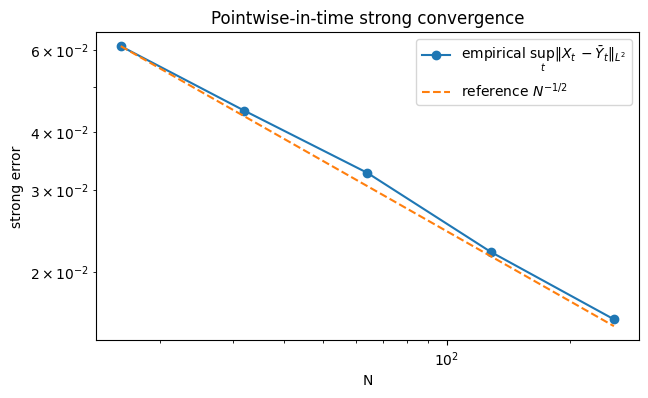

empirical log-log slope = -0.49118520311057795


In [4]:
ref1 = pointwise_L2_sup[0]*np.sqrt(Ns[0]/Ns)
plt.figure(figsize=(7,4))
plt.loglog(Ns, pointwise_L2_sup, 'o-', label=r'empirical $\sup_t\|X_t-\bar Y_t\|_{L^2}$')
plt.loglog(Ns, ref1, '--', label=r'reference $N^{-1/2}$')
plt.xlabel('N'); plt.ylabel('strong error'); plt.title('Pointwise-in-time strong convergence'); plt.legend(); plt.show()
print('empirical log-log slope =', np.polyfit(np.log(Ns), np.log(pointwise_L2_sup), 1)[0])

## Illustration 2 — Theorem 4.3.11
Now estimate
$$
\left(\mathbb E\left[\sup_{t\in[0,T]}|X_t-\bar Y_t^N|^2\right]\right)^{1/2}.
$$
The theorem gives the upper rate
$$
\sqrt{\frac{1+\log N}{N}}.
$$

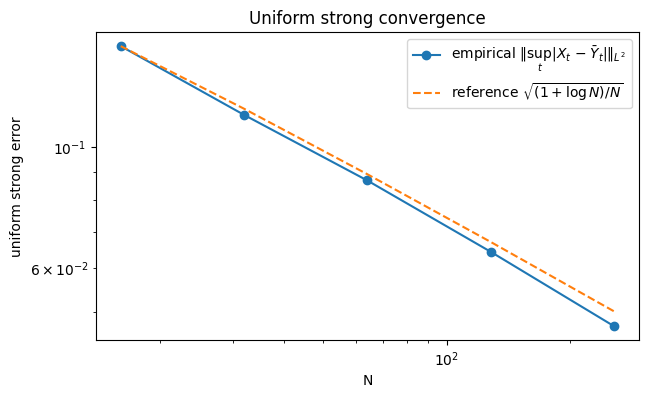

empirical log-log slope = -0.4212152364888935


In [5]:
rate_uniform = np.sqrt((1.0+np.log(Ns))/Ns)
ref2 = uniform_L2[0]*rate_uniform/rate_uniform[0]
plt.figure(figsize=(7,4))
plt.loglog(Ns, uniform_L2, 'o-', label=r'empirical $\|\sup_t|X_t-\bar Y_t|\|_{L^2}$')
plt.loglog(Ns, ref2, '--', label=r'reference $\sqrt{(1+\log N)/N}$')
plt.xlabel('N'); plt.ylabel('uniform strong error'); plt.title('Uniform strong convergence'); plt.legend(); plt.show()
print('empirical log-log slope =', np.polyfit(np.log(Ns), np.log(uniform_L2), 1)[0])

# Summary
The proof of Theorem 4.3.10 rests on the chain
$$
\text{temporal }1/2\text{-Hölder regularity}+\text{Lipschitz coefficients}+\text{BDG}+\text{Gronwall}\Longrightarrow\text{strong Euler convergence}.
$$
For the linearly interpolated Euler–Maruyama scheme,
$$
\sup_t\|X_t-\bar Y_t^N\|_{L^p}=O(N^{-1/2})
$$
and
$$
\left\|\sup_t|X_t-\bar Y_t^N|\right\|_{L^p}=O\left(\sqrt{\frac{1+\log N}{N}}\right).
$$
The order of the supremum and the $L^p$-norm is the key distinction between Theorems 4.3.10 and 4.3.11.